## 1. Imports & Data Loading

**Goal:** Load the dataset, standard data manipulation libraries, and Scikit-Learn validation/metric tools.

This starter cell is ready to run.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, 
    f1_score, 
    classification_report, 
    confusion_matrix, 
    ConfusionMatrixDisplay
)

# Visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", None)

# Load and standardize data
DATA_PATH = "../data/mental_health_analysis.csv"
df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.lower().str.replace(" ", "_")

print(f"Loaded dataset: {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head(3)

Loaded dataset: 5,000 rows, 11 columns


,user_id,age,gender,social_media_hours,exercise_hours,sleep_hours,screen_time_hours,survey_stress_score,wearable_stress_score,support_system,academic_performance
0,1,16,F,9.654486,2.458001,5.198926,8.158189,3,0.288962,Moderate,Excellent
1,2,17,M,9.158143,0.392095,8.866097,5.151993,5,0.409446,Moderate,Good
2,3,15,M,5.028755,0.520119,4.943095,9.209325,2,0.423837,Moderate,Poor


---
## 2. Feature Matrix (X) & Target Vector (y) Definition

### 🎯 Objectives:
1. Extract the target vector `y` from `survey_stress_score`.
2. Construct the feature matrix `X` by dropping non-predictive identifiers and leakage columns.
3. Define separate feature lists for numerical (`numerical_cols`) and categorical (`categorical_cols`) features.

### 💡 Conceptual Explanation & Intuition:
- **Feature Matrix ($X$):** A 2D table where each row is an individual observation (student) and each column is an independent attribute/clue (e.g., `sleep_hours`, `screen_time_hours`) used by the algorithm to make predictions.
- **Target Vector ($y$):** A 1D array of ground-truth labels we want the model to learn to predict (`survey_stress_score`).
- **Target Leakage (Why we drop `wearable_stress_score`):** Target leakage occurs when training features contain information about the target that *would not be available at real-world prediction time*. Since wearable score and survey score were recorded simultaneously as two representations of stress, including the wearable score would allow the model to cheat by simply copying it rather than learning real behavioral patterns from sleep, screen time, and exercise.
- **Identifier Columns (Why we drop `user_id`):** Arbitrary database IDs carry no generalizable predictive relationship to mental stress and could lead to spurious memorization (overfitting).

### 🛠️ Useful Functions:
- Use `df.drop(columns=[...])` to extract feature DataFrame `X` and `df[target_col].copy()` to extract `y`.
- Verify `X.shape` (5000, 8) and `y.shape` (5000,).

In [11]:
# --- Predefined column names and variables ---
target_col = "survey_stress_score"
dropped_cols = ["user_id", "wearable_stress_score", target_col]
numerical_cols = ["age", "social_media_hours", "exercise_hours", "sleep_hours", "screen_time_hours"]
categorical_cols = ["gender", "support_system", "academic_performance"]

# YOUR CODE HERE:
# 1. Define target Series y and feature DataFrame X using the predefined variables
y = df[target_col]
X = df.drop(columns=dropped_cols)


# 2. Print shapes and feature lists to verify
print(X.shape, Y.shape)


(5000, 8) (5000,)


---
## 3. Target Label Zero-Indexing (0-4 Mapping)

### 🎯 Objectives:
1. Shift survey stress scores from human scale (1–5) to zero-indexed machine scale (0–4).
2. Establish a bidirectional mapping dictionary (`label_mapping`) to translate model predictions back to human-interpretable labels.

### 💡 Conceptual Explanation & Intuition:
- **Zero-Indexing (`0` to `K-1`):** In multi-class classification with $K$ classes (here $K=5$), machine learning libraries (such as **XGBoost**, **LightGBM**, **CatBoost**, and neural network **Softmax** loss layers) expect class labels to be consecutive integers starting at `0` (i.e. classes `0, 1, 2, 3, 4`).
- **Why this matters:** Passing 1-indexed classes (`1, 2, 3, 4, 5`) to gradient boosting algorithms triggers `Invalid class label` errors or forces the model to allocate an unnecessary 6th class (index 0) with zero samples.
- **Human-Facing Mapping:** Subtracting `1` (`y_adj = y - 1`) standardizes the data for models; keeping `{0: 1, 1: 2, 2: 3, 3: 4, 4: 5}` ensures seamless translation back to the user-facing scale during inference.

### 🛠️ Useful Functions:
- Use `y - 1` to create zero-indexed target `y_adj`.
- Verify with `sorted(y_adj.unique())` $\rightarrow$ `[0, 1, 2, 3, 4]`.

In [13]:
# --- Predefined mapping for reference ---
label_mapping = {0: 1, 1: 2, 2: 3, 3: 4, 4: 5}

# YOUR CODE HERE:
# 1. Create zero-indexed target Series y_adj (shift classes 1-5 to 0-4)
y_adj = y - 1
print(sorted(y_adj.unique()))  # Verify unique values
# 2. Verify unique values and range of original vs adjusted target
label_mapping = {0: 1, 1: 2, 2: 3, 3: 4, 4: 5}


[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


---
## 4. Train, Validation, and Test Dataset Splitting

### 🎯 Objectives:
1. Split the dataset into three distinct partitions: **60% Train, 20% Validation, 20% Test**.
2. Apply **stratified sampling** (`stratify=y_adj`) in both split stages.
3. Set `random_state=42` to guarantee exact experimental reproducibility.

### 💡 Conceptual Explanation & Intuition:
- **The 3-Way Split Strategy:**
  - **Training Set (60%):** The primary data given to models to learn internal parameters (weights, coefficients, tree splits).
  - **Validation Set (20%):** The "holdout practice exam" used to compare different model families, tune hyperparameters, and detect overfitting before choosing the final candidate.
  - **Test Set (20%):** The "final exam locked in a vault". It must remain completely untouched until the very end to estimate true, unbiased real-world generalization performance.
- **Stratified Splitting (`stratify=...`):** In classification, pure random sampling might randomly place disproportionately more High Stress (Level 5) cases into the Test set and fewer in Training. Stratification forces every split to maintain the exact same proportion of all 5 classes (~20% each) as the full population, preventing sampling bias.
- **The Two-Step Math:**
  - Step 1: Split full dataset into 80% (`X_train_full`) and 20% (`X_test`) with `test_size=0.20`.
  - Step 2: Split `X_train_full` with `test_size=0.25` ($0.25 \times 0.80 = 0.20$), yielding 60% Train and 20% Validation.

### 🛠️ Useful Functions:
- `train_test_split(X, y, test_size=..., stratify=..., random_state=42)` from `sklearn.model_selection`.

In [15]:
# --- Predefined split parameters ---
RANDOM_STATE = 42
TEST_SIZE_INITIAL = 0.20   # 80% train_full, 20% test
TEST_SIZE_VAL = 0.25       # 75% train, 25% val of train_full (60% / 20% overall)

# YOUR CODE HERE:
# 1. First split: 80% train_full, 20% test (stratified)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_adj, test_size=TEST_SIZE_INITIAL, random_state=RANDOM_STATE, stratify=y_adj
)

# 2. Second split: 60% train, 20% validation (stratified)

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=TEST_SIZE_VAL, random_state=RANDOM_STATE, stratify=y_train
)

# 3. Print sizes of each split

print("Train Full Size:", X_train.shape[0])
print("Test Size:", X_test.shape[0])
print("Validation Size:", X_val.shape[0])

Train Full Size: 3000
Test Size: 1000
Validation Size: 1000


---
## 5. Verifying Split Dimensions & Stratification

### 🎯 Objectives:
1. Confirm split row counts match expected proportions (`len(X_train)==3000`, `len(X_val)==1000`, `len(X_test)==1000`).
2. Verify that class percentage distributions across Train, Validation, and Test partitions are uniformly identical (~20% per class).

### 💡 Conceptual Explanation & Intuition:
- **Data Distribution Integrity:** Verifying partition distributions before training prevents subtle data pipeline bugs (e.g. accidental shuffling omission, class leakage, or uneven partitions) from invalidating downstream metric comparisons.
- **Class Support Check:** If one partition had 30% Level 1 and another had 10%, validation scores would be noisy and unreliable.

### 🛠️ Useful Functions:
- `y_train.value_counts(normalize=True).sort_index() * 100` calculates percentage distribution per class.
- Combine series into a summary `pd.DataFrame` to inspect alignment.

In [20]:
# --- Predefined table column names ---
table_columns = ["Full Dataset (%)", "Train Set (%)", "Validation Set (%)", "Test Set (%)"]

# YOUR CODE HERE:
# 1. Calculate class percentages across train, val, test splits
y_train_percentages = y_train.value_counts(normalize=True).sort_index()
y_val_percentages = y_val.value_counts(normalize=True).sort_index()
y_test_percentages = y_test.value_counts(normalize=True).sort_index()

# 2. Display comparison table to confirm uniform stratification

comparison_table = pd.DataFrame({'train': y_train_percentages, 'val': y_val_percentages, 'test': y_test_percentages})
comparison_table = comparison_table.rename(columns={'train': 'Train Set (%)', 'val': 'Validation Set (%)', 'test': 'Test Set (%)'})
comparison_table = (comparison_table * 100).round(2)
comparison_table

,Train Set (%),Validation Set (%),Test Set (%)
survey_stress_score,,,
0,19.63,19.6,19.6
1,20.07,20.1,20.1
2,19.73,19.7,19.8
3,20.23,20.2,20.2
4,20.33,20.4,20.3


---
## 6. Setting Up Evaluation Metrics Strategy

### 🎯 Objectives:
1. Implement a comprehensive evaluation suite computing **Accuracy**, **Macro F1**, **Weighted F1**, **Classification Report**, and **Confusion Matrix**.
2. Encapsulate this logic into a reusable helper function `evaluate_model(y_true, y_pred, model_name)` for benchmark comparisons across all stages.

### 💡 Conceptual Explanation & Intuition:
- **Accuracy (Overall Correctness):** $\text{Accuracy} = \frac{\text{Correct Predictions}}{\text{Total Predictions}}$  
  Measures overall percentage of correct predictions across all 5 classes. While intuitive, accuracy alone can be misleading if class distributions are imbalanced.
- **Precision (Quality & Trustworthiness):** $\text{Precision} = \frac{\text{True Positives}}{\text{True Positives} + \text{False Positives}}$  
  *What it actually is:* When the model predicts "Stress Level 5", how often is it actually correct? High precision means a low false-alarm rate.
- **Recall / Sensitivity (Completeness & Coverage):** $\text{Recall} = \frac{\text{True Positives}}{\text{True Positives} + \text{False Negatives}}$  
  *What it actually is:* Out of all students who are *actually* at Stress Level 5 in reality, what percentage did the model successfully catch? High recall means few missed cases.
- **F1-Score (The Harmonic Balance):** $\text{F1} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$  
  The harmonic mean of Precision and Recall. Unlike a standard arithmetic average, the harmonic mean severely penalizes extreme trade-offs (e.g. 99% precision with 1% recall yields an F1 near 0%, not 50%).
- **Macro F1 (`average="macro"`) — Our Primary Benchmark Metric:**  
  Calculates the F1 score for each of the 5 stress levels independently and computes their **unweighted average**. This guarantees that all stress levels (mild, moderate, severe) are treated with equal importance.
- **Weighted F1 (`average="weighted"`):**  
  Averages per-class F1 scores weighted by the number of true instances (support) of each class in the dataset.
- **Confusion Matrix:**  
  A 5 × 5 matrix where rows represent actual true labels and columns represent model predictions. The diagonal shows correct predictions, while off-diagonal cells highlight exact confusion patterns (e.g. predicting Level 3 instead of Level 4 vs extreme errors).
- **Support:**  
  The count of true instances for each class in the evaluated split.

### 🛠️ Useful Functions:
- `accuracy_score(y_true, y_pred)`
- `f1_score(y_true, y_pred, average="macro")`
- `f1_score(y_true, y_pred, average="weighted")`
- `classification_report(y_true, y_pred, target_names=...)`
- `ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=..., cmap="Blues")`

Evaluation Metrics for Baseline Model (Dummy Predictions):
Accuracy: 0.1900
Weighted F1 Score: 0.1900
Macro F1 Score: 0.1901

Classification Report:
              precision    recall  f1-score   support

     Level 1       0.20      0.20      0.20       196
     Level 2       0.20      0.20      0.20       201
     Level 3       0.20      0.20      0.20       198
     Level 4       0.17      0.17      0.17       202
     Level 5       0.17      0.17      0.17       203

    accuracy                           0.19      1000
   macro avg       0.19      0.19      0.19      1000
weighted avg       0.19      0.19      0.19      1000



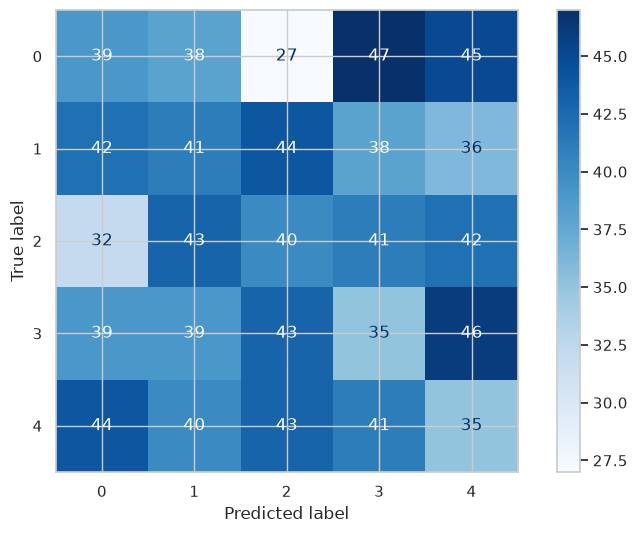

In [25]:
# --- Predefined class and display labels ---


target_names = ["Level 1", "Level 2", "Level 3", "Level 4", "Level 5"]
display_labels = ["Lvl 1", "Lvl 2", "Lvl 3", "Lvl 4", "Lvl 5"]

# YOUR CODE HERE:
# 1. Define evaluate_model(y_true, y_pred, model_name) helper function
def evaluate_model(y_true, y_pred, model_name):
    print(f"Evaluation Metrics for {model_name}:")
    
    
    accuracy = accuracy_score(y_true, y_pred)
    f1_macro = f1_score(y_true, y_pred, average='macro')
    f1_weighted = f1_score(y_true, y_pred, average='weighted')

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Weighted F1 Score: {f1_weighted:.4f}")
    print(f"Macro F1 Score: {f1_macro:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=target_names))
    print(ConfusionMatrixDisplay.from_predictions(y_true, y_pred, cmap='Blues'))

# 2. Test the function with dummy predictions (e.g., matching baseline)
evaluate_model(y_test, y_val, "Baseline Model (Dummy Predictions)")


---
## 7. Summary & Next Steps

### 📝 Key Takeaways from Stage 3:
1. **Feature Matrix ($X$):** 8 features (5 numerical, 3 categorical).
2. **Target ($y$):** 0-indexed (`0, 1, 2, 3, 4`) mapped to stress levels (1–5).
3. **Validation Strategy:** Stratified 60% / 20% / 20% Train-Val-Test split.
4. **Evaluation Setup:** Reusable `evaluate_model` function prioritizing **Macro F1** and **Accuracy**.

➡️ **Next Section:** Section 4 — Preprocessing Pipeline (`ColumnTransformer`) and Logistic Regression Baseline!